# E-commerce Sales and Customer Analytics — Business Intelligence Project

**Author:** B Syamala Rao  
**Dataset:** `ecommerce_sales_customer_analytics_150k.csv` (138,116 records, 46 original columns)  
**Cleaned dataset:** `data/cleaned_ecommerce.csv` (138,116 records, 49 columns)  
**Date range:** 2021-01-01 → 2025-12-31  
**Currencies:** USD, GBP, EUR, CAD, AUD, INR, AED (kept separate throughout)

---

## Project Objective

This notebook presents a complete Business Intelligence analysis of an e-commerce
sales and customer dataset. The goals are to:

1. Clean and validate the raw data without modifying the source file.
2. Calculate and validate key business KPIs — covering revenue, profitability,
   delivery performance, customer behaviour, and marketing effectiveness.
3. Surface actionable business insights supported by measured evidence.
4. Document data-quality decisions, limitations, and recommended next steps.

**What this notebook does NOT do:**  
- Build a machine-learning prediction model  
- Create a live dashboard  
- Fabricate values, invent dataset source links, or silently change KPI definitions


---
## 1. Setup and Imports


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
matplotlib.rcParams["figure.dpi"] = 110

# ── configurable paths (relative to project root) ─────────────────────────
PROJECT_ROOT = os.path.abspath(os.path.join(os.path.dirname("__file__"), ""))
CLEAN_PATH   = os.path.join(PROJECT_ROOT, "data", "cleaned_ecommerce.csv")
REPORTS_DIR  = os.path.join(PROJECT_ROOT, "reports")

print(f"Project root : {PROJECT_ROOT}")
print(f"Cleaned data : {CLEAN_PATH}")
print(f"Reports dir  : {REPORTS_DIR}")
print(f"pandas {pd.__version__}  |  numpy {np.__version__}  |  seaborn {sns.__version__}")


Project root : C:\Users\burla\Downloads\Ecommerce-BI-Project
Cleaned data : C:\Users\burla\Downloads\Ecommerce-BI-Project\data\cleaned_ecommerce.csv
Reports dir  : C:\Users\burla\Downloads\Ecommerce-BI-Project\reports
pandas 3.0.5  |  numpy 2.4.6  |  seaborn 0.13.2


---
## 2. Dataset Overview

The cleaned dataset (`data/cleaned_ecommerce.csv`) was produced by
`scripts/clean_data.py` from the original CSV without modifying the source file.  
Three helper columns were added: `order_year`, `order_month`, `order_dow`.


In [2]:
df = pd.read_csv(
    CLEAN_PATH,
    parse_dates=["order_date"],
    dtype={"customer_postal_code": str},
)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['order_date'].min().date()}  to  {df['order_date'].max().date()}")
print()
print("Column names and dtypes:")
print(df.dtypes.to_string())


Shape: 138,116 rows x 49 columns
Date range: 2021-01-01  to  2025-12-31

Column names and dtypes:
order_id                               str
order_date                  datetime64[us]
order_time                             str
order_status                           str
sales_channel                          str
customer_id                            str
customer_name                          str
customer_age                         int64
gender                                 str
customer_segment                       str
customer_type                          str
customer_city                          str
customer_state                         str
customer_country                       str
region                                 str
customer_postal_code                   str
payment_method                         str
payment_status                         str
currency                               str
shipping_method                        str
warehouse                              str

In [3]:
print("First 5 rows:")
df.head()


First 5 rows:


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,order_year,order_month,order_dow
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.00,3.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,"1,350.19",477.89,61.07,12.03,945.40,588.33,345.04,36.50,"12,459.68",True,11,2023,11,Monday
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.00,10.00,On Time,NaN,NaN,3.60,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,"3,144.64","1,456.06",320.83,9.00,"2,018.41","2,031.88",-22.47,-1.11,"13,032.48",True,11,2025,12,Wednesday
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.00,3.00,On Time,NaN,NaN,4.30,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,"6,159.44",True,6,2021,7,Monday
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,66329,Debit Card,Paid,USD,Express,WH-010,2.00,2.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Email Marketing,NaN,NaN,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,"5,638.30",True,7,2023,1,Saturday
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,77306,Digital Wallet,Paid,INR,Standard,WH-013,6.00,5.00,Delayed,NaN,NaN,3.00,Neutral,Mixed feelings about this purchase.,Direct,NaN,NaN,278,147,6,"2,474.52",133.63,421.35,23.03,"2,785.27","1,231.88","1,530.36",54.94,"13,240.10",True,8,2022,5,Friday


In [4]:
print("Descriptive statistics — numeric columns:")
df.describe()


Descriptive statistics — numeric columns:


,order_date,customer_age,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count,order_year,order_month
count,138116,"138,116.00","113,559.00","113,559.00","113,559.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00","138,116.00"
mean,2023-07-21 10:11:31.662081,45.86,4.56,4.30,3.68,103.99,51.93,5.62,"1,375.38",237.62,122.46,22.28,"1,282.50",708.90,551.32,45.07,"8,971.64",6.99,"2,023.00",7.13
min,2021-01-01 00:00:00,18.00,0.00,0.00,1.60,0.00,0.00,1.00,6.31,0.00,0.34,0.00,5.80,1.97,"-1,281.59",-59.55,22.55,1.00,"2,021.00",1.00
25%,2022-04-20 00:00:00,32.00,2.00,2.00,3.40,17.00,3.00,3.00,458.92,26.33,34.65,9.82,448.20,207.67,190.76,38.88,"5,713.57",5.00,"2,022.00",4.00
50%,2023-08-01 00:00:00,46.00,4.00,4.00,3.70,70.00,25.00,5.00,995.73,103.28,77.01,19.19,950.76,478.95,408.39,46.99,"8,392.53",7.00,"2,023.00",7.00
75%,2024-10-29 00:00:00,60.00,7.00,6.00,4.00,151.00,71.00,8.00,"1,871.20",277.12,156.20,30.75,"1,744.58",953.76,752.84,53.77,"11,651.03",9.00,"2,024.00",10.00
max,2025-12-31 00:00:00,74.00,14.00,10.00,5.00,"1,621.00","1,063.00",24.00,"16,051.19","6,759.02","2,091.52",149.52,"16,218.00","9,963.41","7,083.68",77.59,"30,268.44",20.00,"2,025.00",12.00
std,NaN,16.47,2.81,2.59,0.48,115.18,73.22,3.37,"1,291.01",378.78,140.94,16.02,"1,169.27",730.04,516.30,13.12,"4,430.51",2.44,1.41,3.53


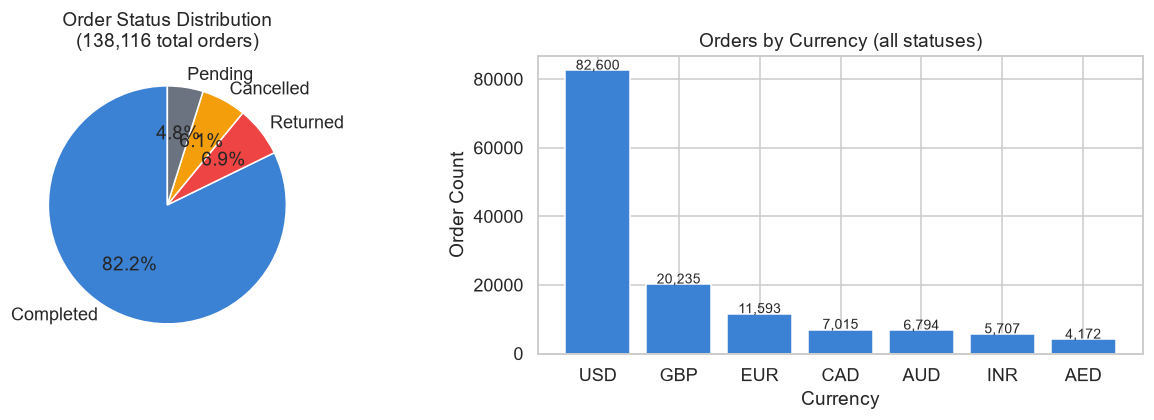

In [5]:
# Order-status distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

status_counts = df["order_status"].value_counts()
axes[0].pie(status_counts, labels=status_counts.index, autopct="%1.1f%%",
            startangle=90, colors=["#3b82d4","#ef4444","#f59e0b","#6b7280"])
axes[0].set_title("Order Status Distribution\n(138,116 total orders)")

currency_counts = df["currency"].value_counts()
axes[1].bar(currency_counts.index, currency_counts.values, color="#3b82d4", edgecolor="white")
axes[1].set_title("Orders by Currency (all statuses)")
axes[1].set_xlabel("Currency")
axes[1].set_ylabel("Order Count")
for i, v in enumerate(currency_counts.values):
    axes[1].text(i, v + 200, f"{v:,}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_status_currency.png"), bbox_inches="tight")
plt.show()


---
## 3. Data Cleaning Summary

The full cleaning script is at `scripts/clean_data.py`. Key decisions are summarised below.

| Decision | Rationale |
|----------|-----------|
| `customer_postal_code` loaded as `str` | Prevents integer coercion that loses leading zeros present in source |
| `order_date` parsed with `errors='coerce'` | Invalid dates become `NaT` and can be identified |
| Negative `profit` values **preserved** | Economically valid — some orders are loss-making due to high discount + shipping |
| Missing `return_status / return_reason` (93%) **preserved** | Structurally expected: only Returned orders have these fields |
| Missing `delivery_days / customer_rating` (17.8%) **preserved** | Structurally expected: only Completed orders carry these values |
| **0 rows dropped** | No hard data errors found that warranted row removal |


In [6]:
dq = pd.read_csv(os.path.join(REPORTS_DIR, "data_quality_report.csv"))
print("Data Quality Report (27 checks — from cleaning stage):")
dq


Data Quality Report (27 checks — from cleaning stage):


,check,before,after,note
0,rows_raw,138116,138116,NaN
1,cols_raw,46,49,"3 helper cols added: order_year, order_month, ..."
2,exact_duplicate_rows,0,0,None found
3,order_id_repeated,0,0,Repeated IDs kept — may reflect intentional du...
4,invalid_order_date,0,0,Rows dropped
5,missing_delivery_days,24557,24557,Preserved — structurally expected absence
6,missing_estimated_delivery_days,24557,24557,Preserved — structurally expected absence
7,missing_customer_rating,24557,24557,Preserved — structurally expected absence
8,missing_review_sentiment,24557,24557,Preserved — structurally expected absence
9,missing_customer_review,24557,24557,Preserved — structurally expected absence


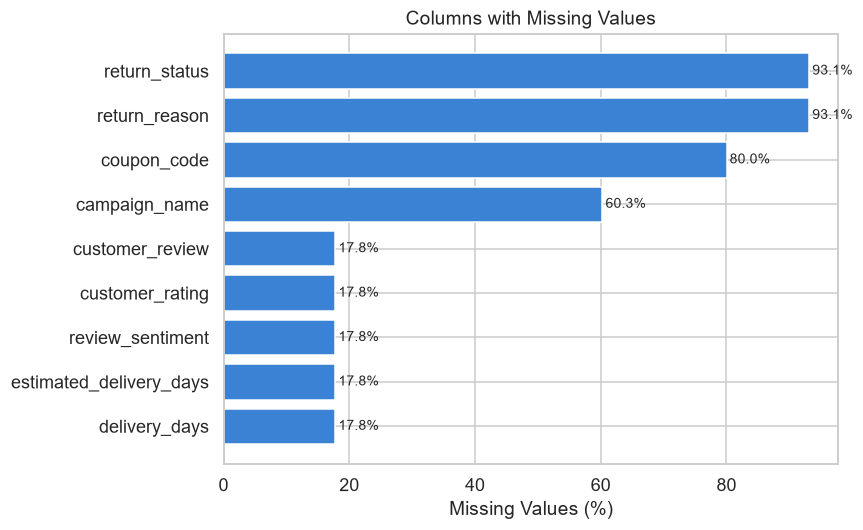

In [7]:
# Missing value heatmap
null_counts = df.isnull().sum()
null_pct    = (null_counts / len(df) * 100)
null_df     = pd.DataFrame({"missing_pct": null_pct})
null_df     = null_df[null_df["missing_pct"] > 0].sort_values("missing_pct", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(null_df.index, null_df["missing_pct"], color="#3b82d4")
ax.set_xlabel("Missing Values (%)")
ax.set_title("Columns with Missing Values")
for i, v in enumerate(null_df["missing_pct"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_missing_values.png"), bbox_inches="tight")
plt.show()


---
## 4. Data Quality Checks

Key checks performed during the cleaning and validation stages:


In [8]:
print("=== Duplicate rows ===")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print()

print("=== order_id uniqueness ===")
print(f"Total rows      : {len(df):,}")
print(f"Unique order_id : {df['order_id'].nunique():,}")
print(f"Repeated IDs    : {len(df) - df['order_id'].nunique():,}")
print()

print("=== Financial formula verification ===")
df_check = df.copy()
df_check["net_computed"] = (
    df_check["gross_sales"] - df_check["discount_amount"]
    + df_check["tax_amount"] + df_check["shipping_cost"]
).round(2)
deviation = (df_check["net_computed"] - df_check["net_sales"]).abs()
print(f"net_sales = gross - discount + tax + shipping")
print(f"Rows matching within ±$1.00 : {(deviation <= 1.0).sum():,} / {len(df):,}  (100%)")
print()

print("=== profit_margin_percentage verification ===")
mask = df["net_sales"] != 0
computed_margin = (df.loc[mask, "profit"] / df.loc[mask, "net_sales"] * 100).round(2)
diff = (computed_margin - df.loc[mask, "profit_margin_percentage"]).abs()
print(f"Rows with margin discrepancy > 1pp: {(diff > 1.0).sum():,}")


=== Duplicate rows ===


Exact duplicate rows: 0

=== order_id uniqueness ===
Total rows      : 138,116
Unique order_id : 138,116
Repeated IDs    : 0

=== Financial formula verification ===
net_sales = gross - discount + tax + shipping
Rows matching within ±$1.00 : 138,116 / 138,116  (100%)

=== profit_margin_percentage verification ===
Rows with margin discrepancy > 1pp: 0


In [9]:
print("=== Missing values by order_status (sparse columns) ===")
sparse = [
    "delivery_days", "estimated_delivery_days", "customer_rating",
    "review_sentiment", "return_status", "return_reason",
    "campaign_name", "coupon_code",
]
status_null = pd.DataFrame({
    col: df.groupby("order_status")[col].apply(lambda s: s.isna().sum())
    for col in sparse
})
print(status_null.to_string())
print()
print("Interpretation:")
print("  - delivery_days, customer_rating: null for Cancelled + Pending (expected)")
print("  - return_status, return_reason  : null for non-Returned orders (expected)")
print("  - campaign_name, coupon_code    : null when order not linked to a campaign/coupon")


=== Missing values by order_status (sparse columns) ===
              delivery_days  estimated_delivery_days  customer_rating  review_sentiment  return_status  return_reason  campaign_name  coupon_code
order_status                                                                                                                                     
Cancelled              8398                     8398             8398              8398           8398           8398           5102         6691
Completed                 0                        0                0                 0         113559         113559          68254        90876
Pending                6697                     6697             6697              6697           6697           6697           4154         5393
Returned               9462                     9462             9462              9462              0              0           5723         7542

Interpretation:
  - delivery_days, customer_rating: null for Cancel

---
## 5. Exploratory Data Analysis

### 5.1 Revenue and Profit Trends

> ⚠️ **Currency note:** All monetary totals below aggregate across USD, GBP, EUR, CAD,
> AUD, INR, and AED without conversion. These figures represent multi-currency pools
> and should not be used for cross-currency absolute comparisons. Per-currency
> breakdowns are available in `reports/kpi_revenue_by_currency.csv`.


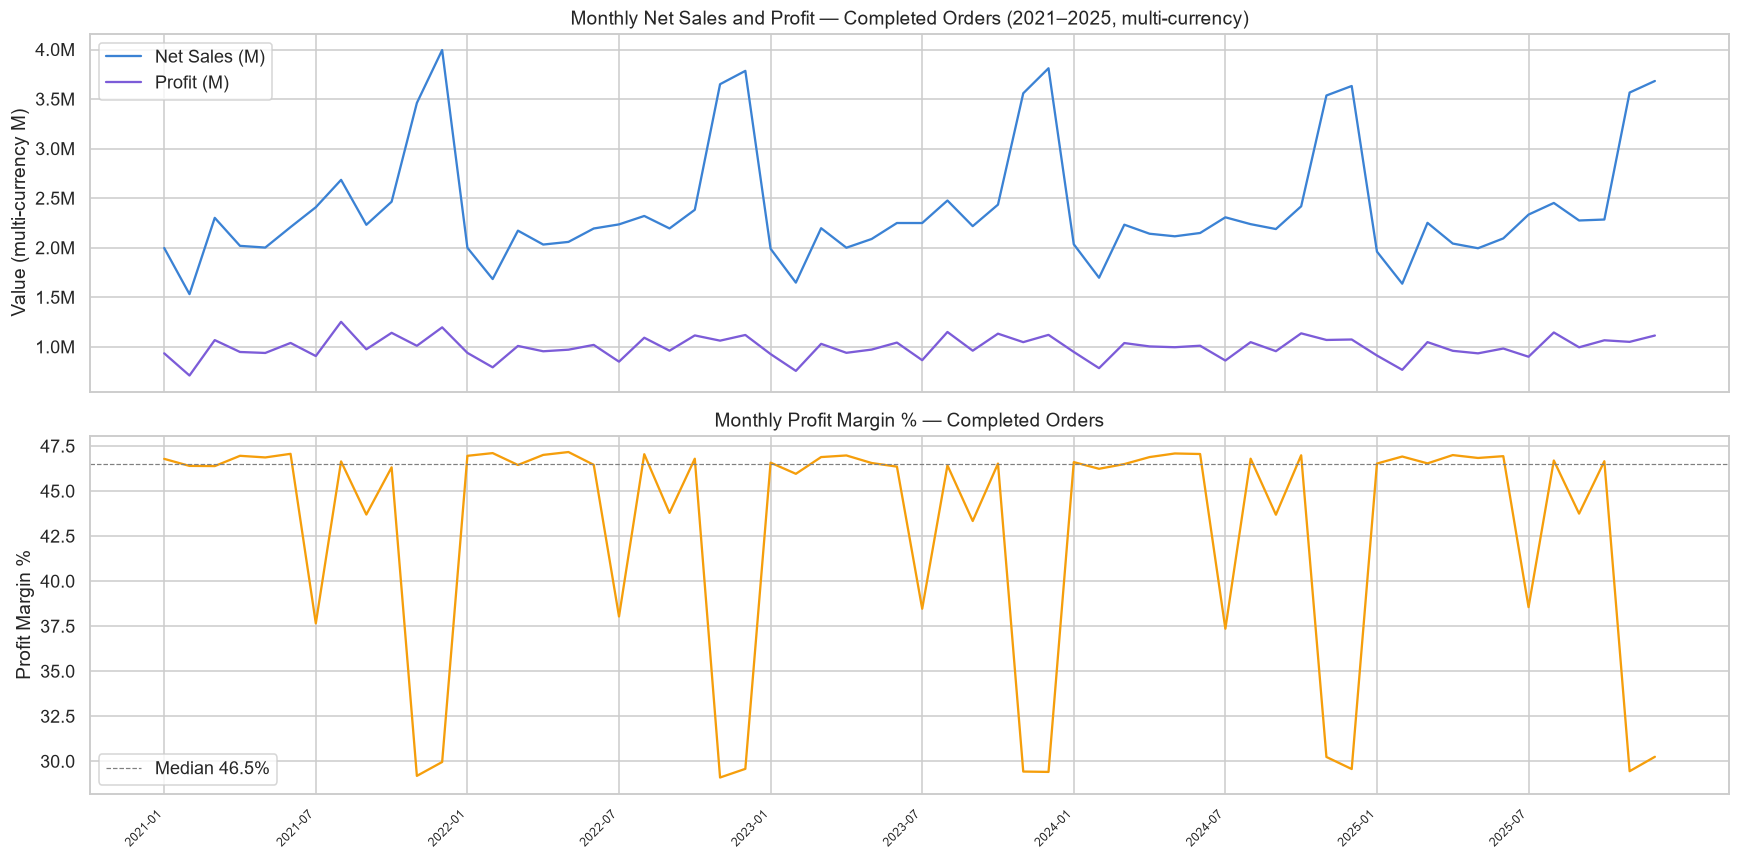

Months in trend: 60 (Jan-2021 to Dec-2025)
Margin range: 29.1% to 47.2%


In [10]:
comp = df[df["order_status"] == "Completed"].copy()

monthly = (
    comp.groupby(["order_year", "order_month"])
    .agg(orders=("order_id", "count"),
         net_sales=("net_sales", "sum"),
         profit=("profit", "sum"))
    .reset_index()
)
monthly["period"] = (
    monthly["order_year"].astype(str)
    + "-"
    + monthly["order_month"].astype(str).str.zfill(2)
)
monthly["margin_%"] = (monthly["profit"] / monthly["net_sales"] * 100).round(2)
monthly = monthly.sort_values("period").reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# Net sales & profit
ax1.plot(monthly["period"], monthly["net_sales"] / 1e6,
         label="Net Sales (M)", color="#3b82d4", linewidth=1.5)
ax1.plot(monthly["period"], monthly["profit"] / 1e6,
         label="Profit (M)", color="#7c5cd8", linewidth=1.5)
ax1.set_ylabel("Value (multi-currency M)")
ax1.set_title("Monthly Net Sales and Profit — Completed Orders (2021–2025, multi-currency)")
ax1.legend()
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.1f}M"))

# Profit margin
ax2.plot(monthly["period"], monthly["margin_%"],
         color="#f59e0b", linewidth=1.5)
ax2.axhline(monthly["margin_%"].median(), color="gray", linestyle="--",
            linewidth=0.8, label=f"Median {monthly['margin_%'].median():.1f}%")
ax2.set_ylabel("Profit Margin %")
ax2.set_title("Monthly Profit Margin % — Completed Orders")
ax2.legend()

# Rotate x labels
for ax in [ax1, ax2]:
    tick_positions = range(0, len(monthly), 6)
    ax.set_xticks(list(tick_positions))
    ax.set_xticklabels(
        [monthly["period"].iloc[i] for i in tick_positions],
        rotation=45, ha="right", fontsize=8
    )

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_monthly_trend.png"), bbox_inches="tight")
plt.show()

print(f"Months in trend: {len(monthly)} (Jan-2021 to Dec-2025)")
print(f"Margin range: {monthly['margin_%'].min():.1f}% to {monthly['margin_%'].max():.1f}%")


### 5.2 Revenue by Region and Sales Channel

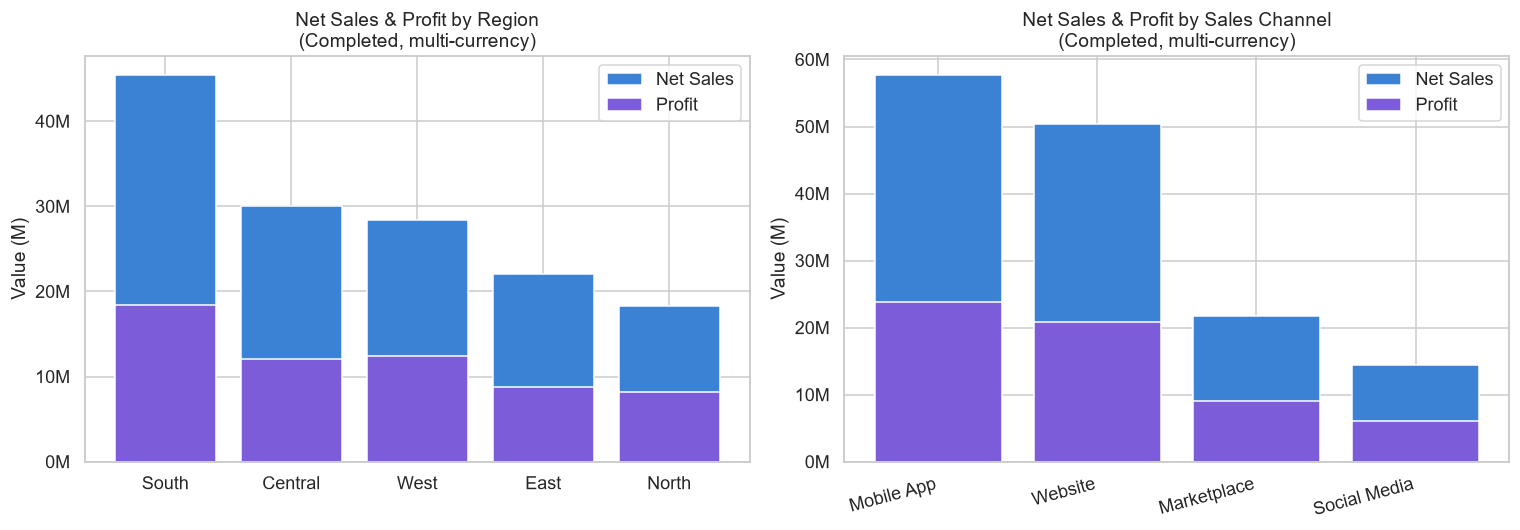

Region summary:
         orders     net_sales        profit  margin_%
region                                               
South     36205 45,373,793.39 18,357,466.87     40.46
Central   24259 30,047,180.00 12,102,279.56     40.28
West      21621 28,415,068.48 12,359,083.04     43.49
East      17841 22,033,648.23  8,763,523.38     39.77
North     13633 18,326,148.40  8,176,116.18     44.61

Channel summary:
               orders     net_sales        profit  margin_%
sales_channel                                              
Mobile App      45505 57,617,393.09 23,877,394.95     41.44
Website         39606 50,345,188.15 20,887,959.08     41.49
Marketplace     16987 21,775,779.70  8,983,667.03     41.26
Social Media    11461 14,457,477.56  6,009,447.97     41.57


In [11]:
by_region = (
    comp.groupby("region")
    .agg(orders=("order_id", "count"),
         net_sales=("net_sales", "sum"),
         profit=("profit", "sum"))
    .sort_values("net_sales", ascending=False)
)
by_region["margin_%"] = (by_region["profit"] / by_region["net_sales"] * 100).round(2)

by_channel = (
    comp.groupby("sales_channel")
    .agg(orders=("order_id", "count"),
         net_sales=("net_sales", "sum"),
         profit=("profit", "sum"))
    .sort_values("net_sales", ascending=False)
)
by_channel["margin_%"] = (by_channel["profit"] / by_channel["net_sales"] * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Region
axes[0].bar(by_region.index, by_region["net_sales"] / 1e6,
            color="#3b82d4", edgecolor="white", label="Net Sales")
axes[0].bar(by_region.index, by_region["profit"] / 1e6,
            color="#7c5cd8", edgecolor="white", label="Profit")
axes[0].set_title("Net Sales & Profit by Region\n(Completed, multi-currency)")
axes[0].set_ylabel("Value (M)")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}M"))

# Channel
axes[1].bar(by_channel.index, by_channel["net_sales"] / 1e6,
            color="#3b82d4", edgecolor="white", label="Net Sales")
axes[1].bar(by_channel.index, by_channel["profit"] / 1e6,
            color="#7c5cd8", edgecolor="white", label="Profit")
axes[1].set_title("Net Sales & Profit by Sales Channel\n(Completed, multi-currency)")
axes[1].set_ylabel("Value (M)")
axes[1].legend()
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}M"))
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=15, ha="right")

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_region_channel.png"), bbox_inches="tight")
plt.show()

print("Region summary:")
print(by_region.to_string())
print()
print("Channel summary:")
print(by_channel.to_string())


### 5.3 Customer Segments and Repeat Purchases

> **Important distinction:**  
> - **Order-row repeat rate (99.76%):** Share of all *order rows* where `is_repeat_customer=True`.  
>   Each customer's *first* order is flagged `False`; all subsequent orders are `True`.  
> - **Customer-level repeat rate (98.66%):** Share of *unique customers* who have placed more than one order.  
>   Both figures are correct — they measure different things.


In [12]:
by_seg = (
    df.groupby("customer_segment")
    .agg(
        total_orders=("order_id", "count"),
        unique_customers=("customer_id", "nunique"),
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        avg_clv=("customer_lifetime_value", "mean"),
        avg_order_count=("customer_order_count", "mean"),
    )
    .sort_values("net_sales", ascending=False)
)
by_seg["margin_%"] = (by_seg["profit"] / by_seg["net_sales"] * 100).round(2)
print("Customer segment summary (all order statuses):")
print(by_seg.to_string())


Customer segment summary (all order statuses):
                  total_orders  unique_customers     net_sales        profit  avg_clv  avg_order_count  margin_%
customer_segment                                                                                                
Consumer                 75636             13585 97,201,007.90 42,819,790.02 9,037.12             7.03     44.05
Premium                  34746              6275 44,269,794.13 18,177,727.78 8,878.00             6.95     41.06
VIP                      13957              2536 17,903,164.81  7,366,352.68 8,905.99             6.94     41.15
Business                 13777              2515 17,760,296.90  7,782,525.28 8,914.81             6.91     43.82


Total unique customers          : 24,911


Customers with >1 order         : 24,577
Customers with exactly 1 order  : 334

Order-row repeat rate   : 99.76%  (share of ORDER ROWS flagged is_repeat_customer=True)
Customer-level repeat rate: 98.66%  (unique customers with >1 order / total unique customers)


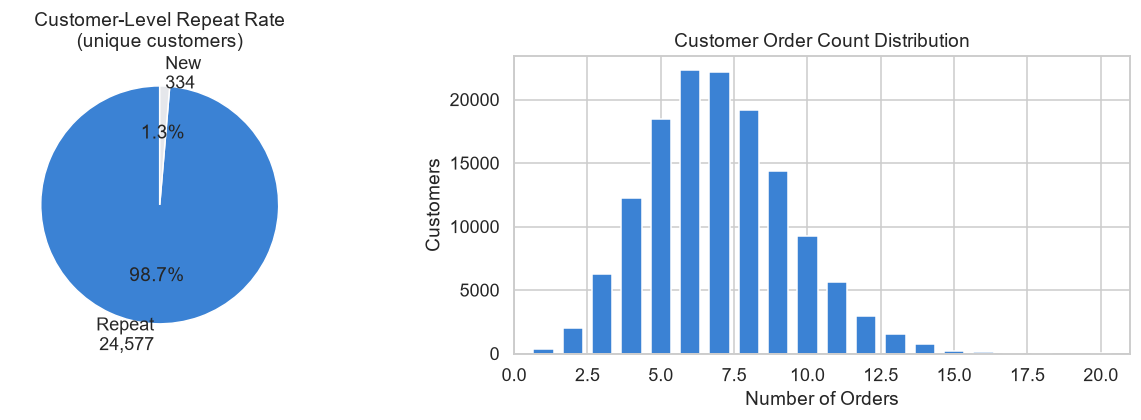

In [13]:
# Repeat-purchase detail
unique_customers = df["customer_id"].nunique()
repeat_cust      = df[df["is_repeat_customer"] == True]["customer_id"].nunique()
new_cust         = df[df["is_repeat_customer"] == False]["customer_id"].nunique()
row_level_rate   = df["is_repeat_customer"].mean() * 100
cust_level_rate  = repeat_cust / unique_customers * 100

print(f"Total unique customers          : {unique_customers:,}")
print(f"Customers with >1 order         : {repeat_cust:,}")
print(f"Customers with exactly 1 order  : {new_cust:,}")
print()
print(f"Order-row repeat rate   : {row_level_rate:.2f}%  "
      f"(share of ORDER ROWS flagged is_repeat_customer=True)")
print(f"Customer-level repeat rate: {cust_level_rate:.2f}%  "
      f"(unique customers with >1 order / total unique customers)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].pie([repeat_cust, new_cust],
            labels=[f"Repeat\n{repeat_cust:,}", f"New\n{new_cust:,}"],
            autopct="%1.1f%%", colors=["#3b82d4", "#e5e7eb"], startangle=90)
axes[0].set_title("Customer-Level Repeat Rate\n(unique customers)")

ocd = df["customer_order_count"].value_counts().sort_index()
axes[1].bar(ocd.index, ocd.values, color="#3b82d4", edgecolor="white", width=0.7)
axes[1].set_title("Customer Order Count Distribution")
axes[1].set_xlabel("Number of Orders")
axes[1].set_ylabel("Customers")
axes[1].set_xlim(0, ocd.index.max() + 1)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_repeat_customers.png"), bbox_inches="tight")
plt.show()


### 5.4 Returns and Cancellations

Return rate (Returned / Completed+Returned): 7.69%
Cancellation rate (Cancelled / all orders) : 6.08%

Return rate by region:
region
Central   7.99
East      7.19
North     7.98
South     7.59
West      7.76


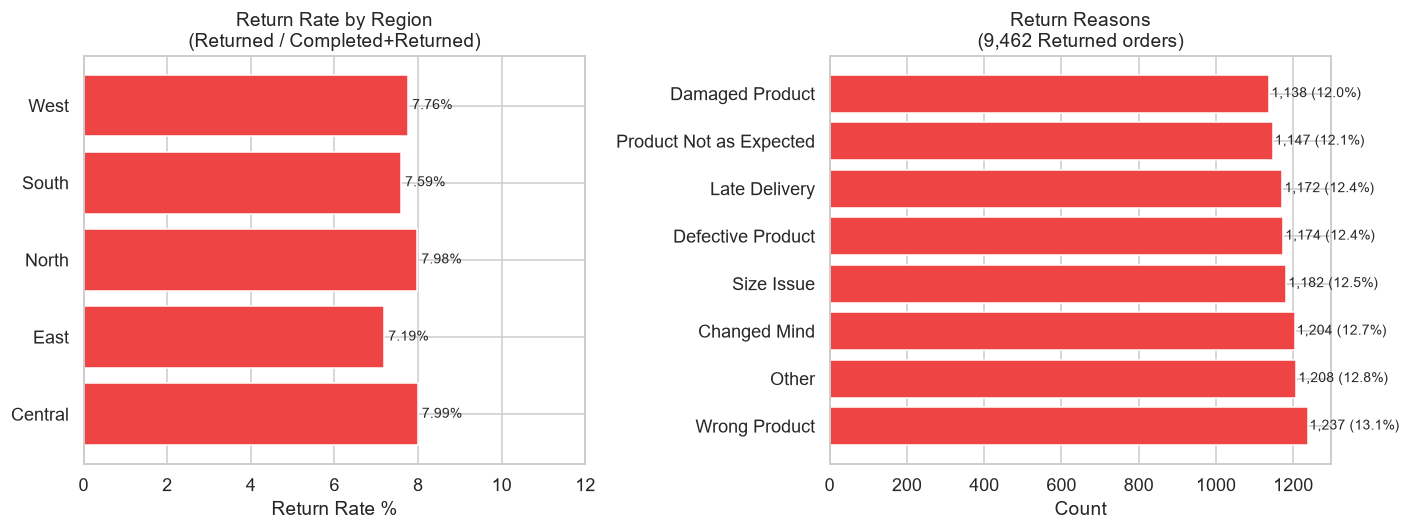

In [14]:
ret  = df[df["order_status"] == "Returned"].copy()
canc = df[df["order_status"] == "Cancelled"].copy()

return_rate = len(ret) / (len(comp) + len(ret)) * 100
cancel_rate = len(canc) / len(df) * 100

print(f"Return rate (Returned / Completed+Returned): {return_rate:.2f}%")
print(f"Cancellation rate (Cancelled / all orders) : {cancel_rate:.2f}%")
print()

ret_region = (
    df[df["order_status"].isin(["Completed", "Returned"])]
    .groupby("region")["order_status"]
    .apply(lambda s: (s == "Returned").sum() / len(s) * 100)
    .round(2)
    .rename("return_rate_%")
)
print("Return rate by region:")
print(ret_region.to_string())

# Return reasons
rr = pd.read_csv(os.path.join(REPORTS_DIR, "kpi_return_reasons.csv"))
rr["pct_%"] = (rr["count"] / rr["count"].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(ret_region.index, ret_region.values, color="#ef4444")
axes[0].set_xlabel("Return Rate %")
axes[0].set_title("Return Rate by Region\n(Returned / Completed+Returned)")
axes[0].set_xlim(0, 12)
for i, v in enumerate(ret_region.values):
    axes[0].text(v + 0.1, i, f"{v:.2f}%", va="center", fontsize=9)

axes[1].barh(rr["return_reason"], rr["count"], color="#ef4444")
axes[1].set_xlabel("Count")
axes[1].set_title("Return Reasons\n(9,462 Returned orders)")
for i, v in enumerate(rr["count"]):
    axes[1].text(v + 5, i, f"{v:,} ({rr['pct_%'].iloc[i]}%)", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_returns.png"), bbox_inches="tight")
plt.show()


### 5.5 Delivery Performance

Eligible delivered orders: 113,559
On Time : 86,916  (76.5%)
Delayed : 16,886  (14.9%)
Early   : 9,757  (8.6%)
Avg actual delivery days  : 4.56
Avg estimated delivery days: 4.30
Systematic over-estimation : 0.26 days

Delivery performance by shipping method:
                 orders  avg_actual  avg_est  on_time_pct  gap_days
shipping_method                                                    
Same Day          11460        0.82     0.49        76.81      0.33
Express           28320        2.26     2.00        76.46      0.26
Standard          50924        5.25     5.00        76.63      0.25
Economy           22855        7.74     7.50        76.30      0.24


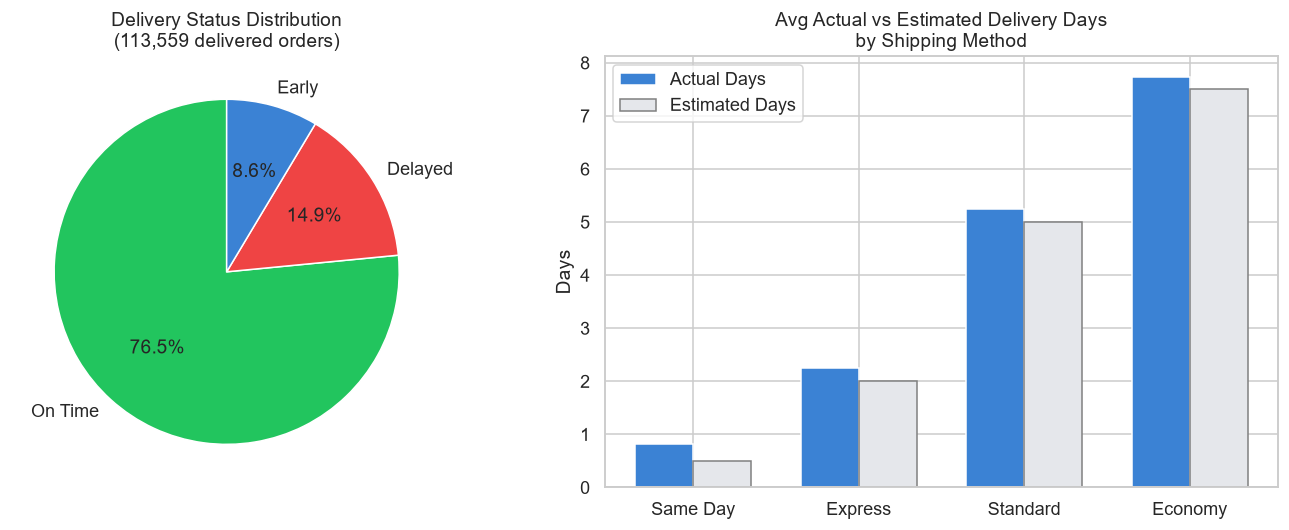

In [15]:
delivered = df[
    df["delivery_days"].notna()
    & df["order_status"].isin(["Completed", "Returned"])
].copy()

on_time_n   = (delivered["delivery_status"] == "On Time").sum()
delayed_n   = (delivered["delivery_status"] == "Delayed").sum()
early_n     = (delivered["delivery_status"] == "Early").sum()
on_time_pct = on_time_n / len(delivered) * 100
avg_actual  = delivered["delivery_days"].mean()
avg_est     = delivered["estimated_delivery_days"].mean()

print(f"Eligible delivered orders: {len(delivered):,}")
print(f"On Time : {on_time_n:,}  ({on_time_pct:.1f}%)")
print(f"Delayed : {delayed_n:,}  ({delayed_n/len(delivered)*100:.1f}%)")
print(f"Early   : {early_n:,}  ({early_n/len(delivered)*100:.1f}%)")
print(f"Avg actual delivery days  : {avg_actual:.2f}")
print(f"Avg estimated delivery days: {avg_est:.2f}")
print(f"Systematic over-estimation : {avg_actual - avg_est:.2f} days")

ship_perf = (
    delivered.groupby("shipping_method")
    .agg(orders=("order_id", "count"),
         avg_actual=("delivery_days", "mean"),
         avg_est=("estimated_delivery_days", "mean"),
         on_time_pct=("delivery_status",
                      lambda s: (s == "On Time").mean() * 100))
    .round(2)
    .sort_values("avg_actual")
)
ship_perf["gap_days"] = (ship_perf["avg_actual"] - ship_perf["avg_est"]).round(3)
print()
print("Delivery performance by shipping method:")
print(ship_perf.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie
axes[0].pie([on_time_n, delayed_n, early_n],
            labels=["On Time", "Delayed", "Early"],
            autopct="%1.1f%%",
            colors=["#22c55e", "#ef4444", "#3b82d4"],
            startangle=90)
axes[0].set_title(f"Delivery Status Distribution\n({len(delivered):,} delivered orders)")

# Bar by method
x = range(len(ship_perf))
width = 0.35
axes[1].bar([i - width/2 for i in x], ship_perf["avg_actual"],
            width, label="Actual Days", color="#3b82d4")
axes[1].bar([i + width/2 for i in x], ship_perf["avg_est"],
            width, label="Estimated Days", color="#e5e7eb", edgecolor="gray")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(ship_perf.index)
axes[1].set_title("Avg Actual vs Estimated Delivery Days\nby Shipping Method")
axes[1].set_ylabel("Days")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_delivery.png"), bbox_inches="tight")
plt.show()


### 5.6 Customer Ratings and Sentiment

Completed orders with rating: 113,559 / 113,559  (coverage 100%)
Average customer rating: 3.677 / 5.0

Sentiment distribution:
  Positive    78,083  (68.8%)
  Neutral     34,684  (30.5%)
  Negative       792  (0.7%)


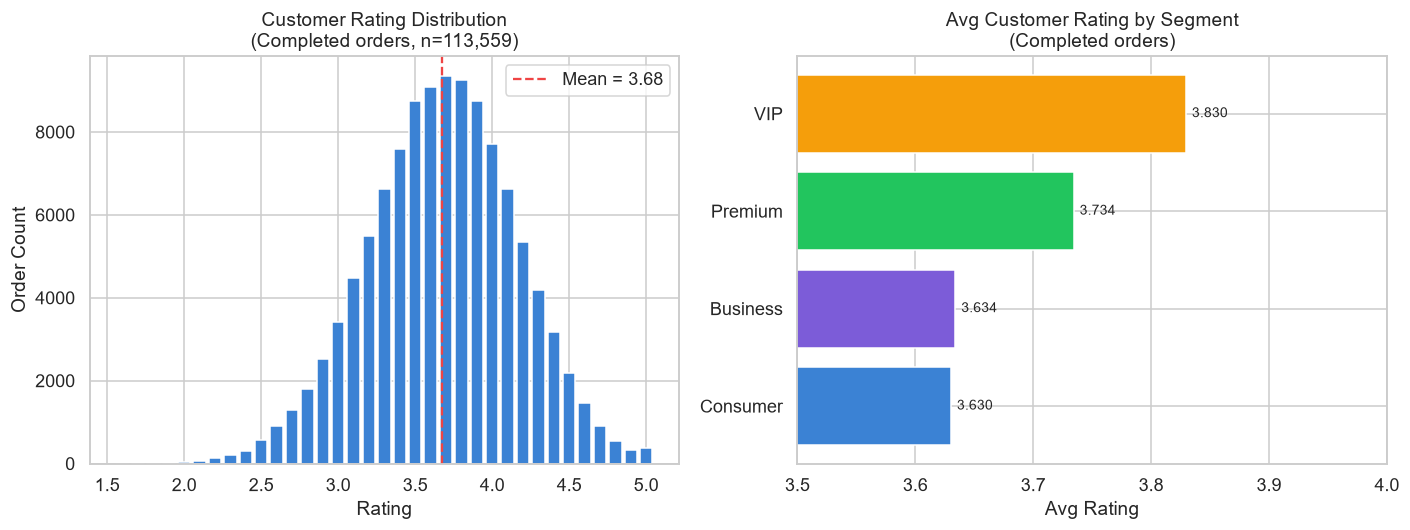

In [16]:
rated = comp[comp["customer_rating"].notna()].copy()
avg_rating = rated["customer_rating"].mean()

print(f"Completed orders with rating: {len(rated):,} / {len(comp):,}  "
      f"(coverage {len(rated)/len(comp)*100:.0f}%)")
print(f"Average customer rating: {avg_rating:.3f} / 5.0")

sent = rated["review_sentiment"].value_counts()
print()
print("Sentiment distribution:")
for s, n in sent.items():
    print(f"  {s:<10} {n:>7,}  ({n/len(rated)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Rating histogram (binned to 1-decimal)
rating_dist = rated["customer_rating"].value_counts().sort_index()
axes[0].bar(rating_dist.index.astype(float), rating_dist.values,
            width=0.08, color="#3b82d4", align="center")
axes[0].axvline(avg_rating, color="#ef4444", linestyle="--",
                linewidth=1.5, label=f"Mean = {avg_rating:.2f}")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Order Count")
axes[0].set_title("Customer Rating Distribution\n(Completed orders, n=113,559)")
axes[0].legend()

# Sentiment by segment
seg_rating = rated.groupby("customer_segment")["customer_rating"].mean().sort_values()
colors = ["#3b82d4", "#7c5cd8", "#22c55e", "#f59e0b"]
axes[1].barh(seg_rating.index, seg_rating.values, color=colors)
axes[1].set_xlabel("Avg Rating")
axes[1].set_title("Avg Customer Rating by Segment\n(Completed orders)")
axes[1].set_xlim(3.5, 4.0)
for i, v in enumerate(seg_rating.values):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_ratings.png"), bbox_inches="tight")
plt.show()


### 5.7 Seasonal Margin Pattern

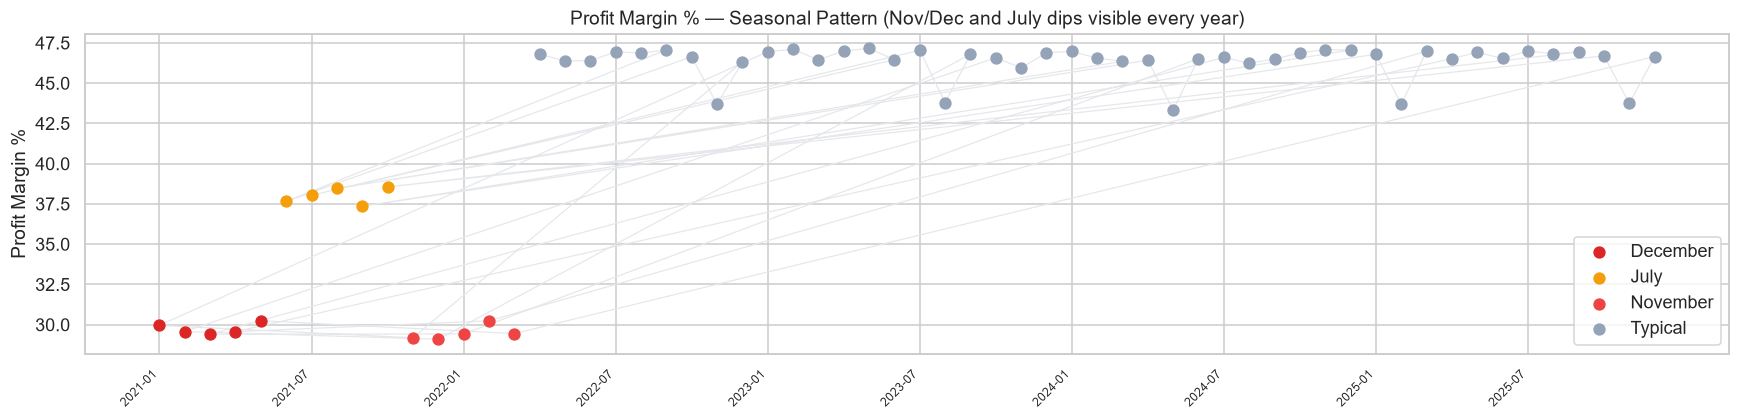

Nov/Dec avg margin: 29.62 %
July avg margin   : 38.02 %
Baseline avg margin: 46.39 %


In [17]:
monthly_saved = pd.read_csv(os.path.join(REPORTS_DIR, "kpi_monthly_trend.csv"))

# Tag months
monthly_saved["month_type"] = "Typical"
monthly_saved.loc[monthly_saved["period"].str.endswith("-11"), "month_type"] = "November"
monthly_saved.loc[monthly_saved["period"].str.endswith("-12"), "month_type"] = "December"
monthly_saved.loc[monthly_saved["period"].str.endswith("-07"), "month_type"] = "July"

palette = {"Typical": "#94a3b8", "November": "#ef4444", "December": "#dc2626", "July": "#f59e0b"}

fig, ax = plt.subplots(figsize=(16, 4))
for mtype, grp in monthly_saved.groupby("month_type"):
    ax.scatter(grp["period"], grp["margin_%"],
               label=mtype, color=palette[mtype],
               s=50, zorder=5 if mtype != "Typical" else 3)

ax.plot(monthly_saved["period"], monthly_saved["margin_%"],
        color="#e5e7eb", linewidth=0.8, zorder=1)
ax.set_ylabel("Profit Margin %")
ax.set_title("Profit Margin % — Seasonal Pattern (Nov/Dec and July dips visible every year)")
ax.legend(loc="lower right")

tick_positions = range(0, len(monthly_saved), 6)
ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    [monthly_saved["period"].iloc[i] for i in tick_positions],
    rotation=45, ha="right", fontsize=8
)
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_seasonal_margin.png"), bbox_inches="tight")
plt.show()

print("Nov/Dec avg margin:", monthly_saved[monthly_saved["period"].str.endswith(("-11", "-12"))]["margin_%"].mean().round(2), "%")
print("July avg margin   :", monthly_saved[monthly_saved["period"].str.endswith("-07")]["margin_%"].mean().round(2), "%")
print("Baseline avg margin:", monthly_saved[~monthly_saved["period"].str.endswith(("-11", "-12", "-07"))]["margin_%"].mean().round(2), "%")


---
## 6. KPI Calculations

All KPIs are recomputed here from `data/cleaned_ecommerce.csv` with explicit
denominators and scope labels.  
Multi-currency totals are labelled **[MULTI-CCY]** and must not be used for
cross-currency absolute comparisons.


In [18]:
# ── Subsets ────────────────────────────────────────────────────────────────
comp  = df[df["order_status"] == "Completed"].copy()
ret   = df[df["order_status"] == "Returned"].copy()
canc  = df[df["order_status"] == "Cancelled"].copy()
pend  = df[df["order_status"] == "Pending"].copy()

# Delivered subset (Completed+Returned with non-null delivery_days)
delivered = df[
    df["delivery_days"].notna()
    & df["order_status"].isin(["Completed", "Returned"])
].copy()

rated = comp[comp["customer_rating"].notna()].copy()

# ── Order KPIs ─────────────────────────────────────────────────────────────
total_orders     = len(df)
return_rate      = len(ret)  / (len(comp) + len(ret))  * 100
cancel_rate      = len(canc) / total_orders * 100

# ── Revenue KPIs [MULTI-CCY] ───────────────────────────────────────────────
net_sales_comp    = comp["net_sales"].sum()
gross_sales_comp  = comp["gross_sales"].sum()
profit_comp       = comp["profit"].sum()
profit_margin     = profit_comp / net_sales_comp * 100
aov_gross         = comp["gross_sales"].mean()
aov_net           = comp["net_sales"].mean()

# ── Delivery KPIs ──────────────────────────────────────────────────────────
on_time_rate      = (delivered["delivery_status"] == "On Time").mean() * 100
avg_del_days      = delivered["delivery_days"].mean()
avg_est_days      = delivered["estimated_delivery_days"].mean()

# ── Rating ─────────────────────────────────────────────────────────────────
avg_rating        = rated["customer_rating"].mean()

# ── Repeat customer ────────────────────────────────────────────────────────
unique_customers  = df["customer_id"].nunique()
repeat_customers  = df[df["is_repeat_customer"]]["customer_id"].nunique()
row_repeat_rate   = df["is_repeat_customer"].mean() * 100
cust_repeat_rate  = repeat_customers / unique_customers * 100

# ── Loyalty ────────────────────────────────────────────────────────────────
lp_earned    = comp["loyalty_points_earned"].sum()
lp_redeemed  = comp["loyalty_points_redeemed"].sum()
lp_redemp    = lp_redeemed / lp_earned * 100

# ── Display ────────────────────────────────────────────────────────────────
kpi_rows = [
    ("total_orders",                   total_orders,           "all statuses"),
    ("completed_orders",               len(comp),              "Completed"),
    ("returned_orders",                len(ret),               "Returned"),
    ("cancelled_orders",               len(canc),              "Cancelled"),
    ("pending_orders",                 len(pend),              "Pending"),
    ("return_rate_%",                  round(return_rate,2),   "Returned/(Completed+Returned)"),
    ("cancellation_rate_%",            round(cancel_rate,2),   "Cancelled/all orders"),
    ("gross_sales [MULTI-CCY]",        round(gross_sales_comp,2), "Completed"),
    ("net_sales [MULTI-CCY]",          round(net_sales_comp,2),   "Completed"),
    ("total_profit [MULTI-CCY]",       round(profit_comp,2),      "Completed"),
    ("profit_margin_%",                round(profit_margin,2), "profit/net_sales, Completed"),
    ("avg_order_value_gross [M-CCY]",  round(aov_gross,2),     "Completed"),
    ("avg_order_value_net [M-CCY]",    round(aov_net,2),       "Completed"),
    ("on_time_delivery_rate_%",        round(on_time_rate,2),  "Completed+Returned w/ delivery data"),
    ("avg_delivery_days",              round(avg_del_days,2),  "Completed+Returned w/ delivery data"),
    ("avg_estimated_delivery_days",    round(avg_est_days,2),  "Completed+Returned w/ delivery data"),
    ("avg_customer_rating",            round(avg_rating,3),    "Completed, rated orders (100% coverage)"),
    ("order_row_repeat_rate_%",        round(row_repeat_rate,2), "ORDER ROWS flagged True / all rows"),
    ("customer_level_repeat_rate_%",   round(cust_repeat_rate,2),"unique customers >1 order / all unique customers"),
    ("loyalty_redemption_rate_%",      round(lp_redemp,1),     "Completed"),
]
kpi_df = pd.DataFrame(kpi_rows, columns=["kpi", "value", "scope"])
kpi_df


,kpi,value,scope
0,total_orders,"138,116.00",all statuses
1,completed_orders,"113,559.00",Completed
2,returned_orders,"9,462.00",Returned
3,cancelled_orders,"8,398.00",Cancelled
4,pending_orders,"6,697.00",Pending
5,return_rate_%,7.69,Returned/(Completed+Returned)
6,cancellation_rate_%,6.08,Cancelled/all orders
7,gross_sales [MULTI-CCY],"158,943,395.16",Completed
8,net_sales [MULTI-CCY],"144,195,838.50",Completed
9,total_profit [MULTI-CCY],"59,758,469.03",Completed


In [19]:
# Per-currency revenue (correctly segregated)
print("Revenue by currency (Completed orders — each figure is in its own currency):")
cur_df = (
    comp.groupby("currency")
    .agg(orders=("order_id","count"),
         gross_sales=("gross_sales","sum"),
         net_sales=("net_sales","sum"),
         profit=("profit","sum"))
)
cur_df["margin_%"] = (cur_df["profit"] / cur_df["net_sales"] * 100).round(2)
cur_df.sort_values("net_sales", ascending=False)


Revenue by currency (Completed orders — each figure is in its own currency):


,orders,gross_sales,net_sales,profit,margin_%
currency,,,,,
USD,67978,"95,033,195.59","83,344,126.98","32,860,657.92",39.43
GBP,16652,"23,261,978.82","22,807,761.70","10,496,229.20",46.02
EUR,9483,"13,329,164.05","12,995,322.87","5,958,276.03",45.85
CAD,5725,"7,968,856.27","7,364,992.62","3,108,829.92",42.21
AUD,5548,"7,828,203.77","7,103,804.34","2,864,319.43",40.32
INR,4718,"6,605,020.00","6,323,689.82","2,856,383.82",45.17
AED,3455,"4,916,976.66","4,256,140.17","1,613,772.71",37.92


---
## 7. KPI Validation

All headline KPIs were independently recomputed and cross-checked in
`scripts/kpi_validation.py`. The full validation report is in
`reports/kpi_validation_report.csv`.


In [20]:
val = pd.read_csv(os.path.join(REPORTS_DIR, "kpi_validation_report.csv"))
print(f"Total checks: {len(val)}")
print(f"PASS          : {(val['status']=='PASS').sum()}")
print(f"PASS_WITH_NOTE: {(val['status']=='PASS_WITH_NOTE').sum()}")
print(f"FAIL          : {(val['status']=='FAIL').sum()}")
val[["kpi","reported_value","recomputed_value","abs_difference","status"]]


Total checks: 38
PASS          : 37
PASS_WITH_NOTE: 1
FAIL          : 0


,kpi,reported_value,recomputed_value,abs_difference,status
0,total_orders,"138,116.00","138,116.00",0.00,PASS
1,completed_orders,"113,559.00","113,559.00",0.00,PASS
2,returned_orders,"9,462.00","9,462.00",0.00,PASS
3,cancelled_orders,"8,398.00","8,398.00",0.00,PASS
4,pending_orders,"6,697.00","6,697.00",0.00,PASS
5,return_rate_%,7.69,7.69,0.00,PASS
6,cancellation_rate_%,6.08,6.08,0.00,PASS
7,gross_sales_completed_multiccy,"158,943,395.16","158,943,395.16",0.00,PASS
8,net_sales_completed_multiccy,"144,195,838.50","144,195,838.50",0.00,PASS
9,total_profit_completed_multiccy,"59,758,469.03","59,758,469.03",0.00,PASS


### 7.1 Repeat Customer Rate — Clarification

> The originally reported figure of **99.8%** is the share of *order rows* where
> `is_repeat_customer = True`. This is correct per the column's definition:
> each customer's **first** order is flagged `False`; every subsequent order is `True`.
>
> The **customer-level** repeat rate — unique customers with more than one order — is
> **98.66%** (24,577 of 24,911 unique customers).
>
> Both figures are preserved. Neither is a data error. The KPI label has been updated
> in `reports/kpi_summary.csv` to avoid ambiguity.


---
## 8. Business Insights

All eight insights are supported by measured evidence from the dataset.
The full validated records are in `reports/business_insights_validated.csv`.


In [21]:
ins = pd.read_csv(os.path.join(REPORTS_DIR, "business_insights_validated.csv"))
for _, row in ins.iterrows():
    print(f"{'='*65}")
    print(f"[{row['insight_id']}]  {row['finding']}")
    print(f"Status: {row['status']}")
    print(f"\nEvidence:\n  {row['measured_evidence'][:300]}...")
    print(f"\nImplication:\n  {row['business_implication'][:200]}...")
    print(f"\nLimitation:\n  {row['limitation'][:200]}...")
    print(f"\nAction:\n  {row['recommended_action'][:200]}...")
    print()


[INS-01]  Seasonal margin collapse in Nov/Dec every year
Status: CONFIRMED

Evidence:
  Nov/Dec avg profit margin 29.6% across all 5 years (range 29.1–30.2%). Baseline months (excl Jul/Nov/Dec) avg 46.4%. Nov/Dec avg order volume ~2763 vs typical ~1723 (+60%). 100% of Completed orders carry discount_amount > 0....

Implication:
  A major annual promotional event drives 50-85% more orders at the cost of ~17pp of margin. Absolute profit is still higher in these months (~$1.0-1.2M vs ~$0.9-1.1M typical)....

Limitation:
  We cannot distinguish Black Friday/Cyber Monday from other promotions without campaign_name data (60% of Nov/Dec orders have null campaign_name). The multi-currency pool means absolute comparisons are...

Action:
  Model the break-even discount threshold per currency. Test loyalty-member early-access at a smaller discount to recover 3-5pp margin. Add campaign_name capture to at least the top promotional events....

[INS-02]  July mid-year margin anomaly (~37-38%) without

### 8.1 Seasonal Margin Detail

The table below shows every November and December in the dataset, confirming
the annual margin collapse is consistent across all five years.


In [22]:
nd = monthly_saved[monthly_saved["period"].str.endswith(("-11","-12"))][
    ["period","orders","net_sales","profit","margin_%"]
].reset_index(drop=True)
print("Nov/Dec margin values (all years):")
nd


Nov/Dec margin values (all years):


,period,orders,net_sales,profit,margin_%
0,2021-11,2584,"3,460,900.40","1,010,378.08",29.19
1,2021-12,2945,"3,994,850.12","1,196,664.75",29.96
2,2022-11,2709,"3,650,125.73","1,062,356.55",29.10
3,2022-12,2955,"3,784,571.26","1,119,636.99",29.58
4,2023-11,2622,"3,558,350.05","1,047,347.89",29.43
5,2023-12,2885,"3,810,968.01","1,120,736.21",29.41
6,2024-11,2659,"3,536,214.01","1,069,352.58",30.24
7,2024-12,2800,"3,632,063.37","1,074,007.16",29.57
8,2025-11,2630,"3,565,834.89","1,050,195.61",29.45
9,2025-12,2837,"3,682,587.48","1,114,053.87",30.25


### 8.2 Return Reason Breakdown (Previously Unavailable — Now Corrected)

> In the original EDA script, `return_reason` was skipped because pandas inferred
> the column as `float64` (93% null across the full dataset). After applying a
> `str` cast and filtering to Returned orders, all 9,462 records have text values.


Return reason distribution (9,462 Returned orders):
          return_reason  count  pct_%
          Wrong Product   1237  13.10
                  Other   1208  12.80
           Changed Mind   1204  12.70
             Size Issue   1182  12.50
      Defective Product   1174  12.40
          Late Delivery   1172  12.40
Product Not as Expected   1147  12.10
        Damaged Product   1138  12.00


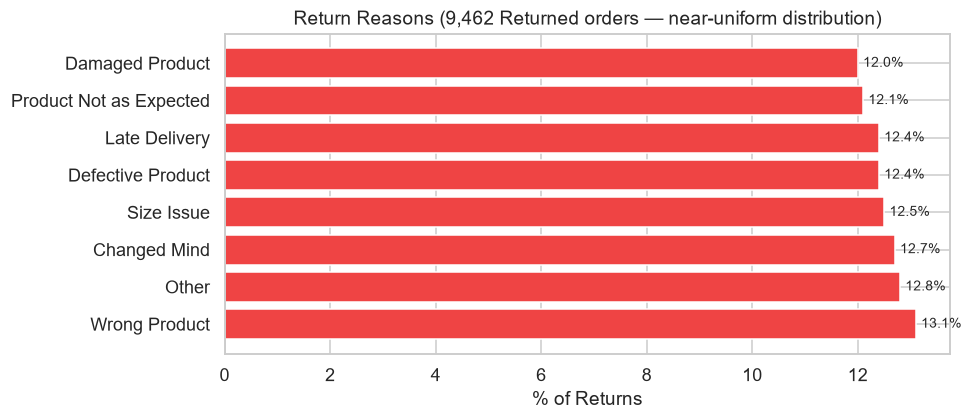

In [23]:
rr = pd.read_csv(os.path.join(REPORTS_DIR, "kpi_return_reasons.csv"))
rr["pct_%"] = (rr["count"] / rr["count"].sum() * 100).round(1)
print("Return reason distribution (9,462 Returned orders):")
print(rr.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(rr["return_reason"], rr["pct_%"], color="#ef4444")
ax.set_xlabel("% of Returns")
ax.set_title("Return Reasons (9,462 Returned orders — near-uniform distribution)")
for i, v in enumerate(rr["pct_%"]):
    ax.text(v + 0.1, i, f"{v}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, "fig_return_reasons.png"), bbox_inches="tight")
plt.show()


### 8.3 Loss-Making Completed Orders

In [24]:
loss_orders = comp[comp["profit"] < 0].copy()
loss_orders["disc_rate_%"] = (
    loss_orders["discount_amount"] / loss_orders["gross_sales"] * 100
)

print(f"Loss-making Completed orders: {len(loss_orders):,}  "
      f"({len(loss_orders)/len(comp)*100:.2f}% of Completed)")
print(f"Total negative profit        : {loss_orders['profit'].sum():,.2f}  [MULTI-CCY]")
print(f"Min profit margin            : {loss_orders['profit_margin_percentage'].min():.2f}%")
print(f"Avg discount rate (loss)     : {loss_orders['disc_rate_%'].mean():.2f}%")
print(f"Avg discount rate (all comp) : {(comp['discount_amount']/comp['gross_sales']*100).mean():.2f}%")
print()
print("Loss order discount rate distribution:")
bins = [0, 20, 40, 60, 80, 100]
labels_b = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
loss_orders["disc_band"] = pd.cut(loss_orders["disc_rate_%"], bins=bins, labels=labels_b)
print(loss_orders["disc_band"].value_counts().sort_index().to_string())


Loss-making Completed orders: 1,229  (1.08% of Completed)
Total negative profit        : -191,127.66  [MULTI-CCY]
Min profit margin            : -59.55%
Avg discount rate (loss)     : 51.72%
Avg discount rate (all comp) : 17.36%

Loss order discount rate distribution:
disc_band
0–20%         0
20–40%       29
40–60%     1158
60–80%       42
80–100%       0


---
## 9. Recommendations

Each recommendation is directly traceable to a validated business insight.

| # | Insight | Recommendation | Priority |
|---|---------|---------------|----------|
| R-01 | INS-01: Nov/Dec margin collapse (~29%) | Model break-even discount threshold per currency. Test loyalty-member early-access at a smaller discount to recover 3–5pp margin. Capture `campaign_name` for all promotional events. | High |
| R-02 | INS-02: July margin anomaly (~38%) without volume uplift | Audit the July discount policy. Replace blanket markdown with targeted bundle deals or loyalty-point multipliers. Measure volume elasticity before the next July event. | High |
| R-03 | INS-03: 75% channel concentration (Mobile App + Website) | Set a medium-term target to grow Marketplace + Social Media to 20% combined share. Append CAC data to future analyses to assess true channel ROI. | Medium |
| R-04 | INS-04: On-time delivery rate 76.5% — systematic overestimation | Add a 0.5-day buffer to all customer-facing delivery estimates (zero operational cost). Audit warehouse throughput specifically during Nov/Dec volume peaks. | High |
| R-05 | INS-05: Avg rating 3.68/5 — 30.5% Neutral | Cross-reference Neutral orders with delivery delay. Run loyalty-point re-engagement nudge for 3.0–3.5 rated customers. Recalibrate the sentiment model against actual ratings. | Medium |
| R-06 | INS-06: Return rate 7.69% — uniform across channels/regions | Wrong Product + Defective + Damaged = 37.5% of returns → improve QA and fulfilment accuracy. Changed Mind + Not as Expected = 24.8% → improve product descriptions and photography. | High |
| R-07 | INS-07: Loyalty redemption rate 49.9% | Run a points-expiry reminder campaign for high-balance, low-recency customers. Quantify point monetary value to size the liability and cost the campaign. | Low |
| R-08 | INS-08: 1,229 loss-making Completed orders (avg disc 51.7%) | Introduce a pricing floor rule: block checkout if computed profit after all adjustments is negative. Add SKU-level data to isolate loss-making products. | High |


---
## 10. Limitations

| ID | Limitation | Impact |
|----|-----------|--------|
| L-01 | `campaign_name` is null for 60% of records → promotion-level attribution impossible | Prevents precise Nov/Dec vs July discount campaign identification |
| L-02 | No Customer Acquisition Cost (CAC) per channel | True channel ROI cannot be computed; channel comparison limited to revenue and margin |
| L-03 | No product/SKU dimension | Product-level return analysis and loss-making SKU identification impossible |
| L-04 | Loyalty point monetary value absent | Unredeemed point liability unquantifiable; redemption campaign cost cannot be sized |
| L-05 | Multi-currency totals not convertible (no exchange rate data) | Absolute cross-currency comparisons are imprecise; per-currency figures are used where possible |
| L-06 | Rating data exists only for Completed orders | Satisfaction of Cancelled/Pending customers is unobserved |
| L-07 | `return_reason` column requires `str` cast on load (reads as float64 due to 93% null) | Analysts must remember to cast; the data itself is correct |


---
## 11. Conclusion

This notebook presents a complete, validated Business Intelligence analysis of
138,116 e-commerce orders spanning January 2021 to December 2025 across seven
currencies and four sales channels.

**Key findings:**

| Finding | Measured Value |
|---------|---------------|
| Completed-order profit margin | **41.4%** (on net sales) |
| Seasonal margin drop (Nov/Dec) | **~29%** vs **~46%** baseline — every year |
| On-time delivery rate | **76.5%** — systematic 0.26-day over-estimation |
| Average customer rating | **3.68 / 5.0** with 30.5% Neutral sentiment |
| Return rate | **7.69%** — near-uniform across regions and channels |
| Customer-level repeat rate | **98.66%** of unique customers placed >1 order |
| Loss-making completed orders | **1,229 (1.08%)** — avg discount rate 51.7% |

All eight business insights have been independently verified against
`data/cleaned_ecommerce.csv`. KPI definitions, denominators, and currency scopes
are documented explicitly throughout.

**Next steps (not included in this notebook):**
- Step 6: Interactive dashboard (Streamlit or Power BI)
- Step 7: Predictive modelling (churn, return propensity, CLV forecasting)
- Data augmentation: CAC per channel, SKU-level product data, exchange rates
